# AIDA 2156 Project Exercise 04 – Category and Channel Relationships

**Question:** Do onboarding task types appear in different proportions across the fictional intake channels?

This notebook uses the original synthetic `requests.csv` from AIDA 1141 Exercise 02. One row represents one onboarding task, and the five task types are the request categories. It builds a task type × channel contingency table, compares the task-type mix within each channel, and briefly checks whether the pattern differs between field and office departments.

 The analysis describes patterns in synthetic data. It does not establish that intake channel causes differences in task type, or that task type causes channel choice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

DATA_PATH = Path("../../../AIDA-1141/project-labs/02-synthetic-request-records/data/requests.csv")
EX01_COUNTS = Path("../01-intake-volume-profile/outputs/intake_counts.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Only truly empty cells become missing (NaN); the text "not_applicable" stays as a value
requests = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])
print(f"Loaded {len(requests):,} requests")

Loaded 2,064 requests


## A. Data checks

The notebook checks that request and employee IDs are complete and request IDs are unique. It also checks that task type, intake channel, and confirmed hiring department are complete and contain the documented categories, and that each employee has one confirmed hiring department.

The task type × channel counts are compared with the table saved in AIDA 2156 Exercise 01 to confirm that the two summaries agree.

In [2]:
CHANNELS = ["web_form", "email", "phone"]
TASK_TYPES = ["payroll_setup", "system_access", "orientation_scheduling", "workplace_access", "equipment_setup"]
FIELD_DEPARTMENTS = ["Parks", "Transit", "Utilities"]
OFFICE_DEPARTMENTS = ["Recreation", "Finance", "Administration"]

ex01_counts = pd.read_csv(EX01_COUNTS, index_col=0)
counts = pd.crosstab(requests["task_type"], requests["intake_channel"], margins=True, margins_name="Total")
counts = counts.reindex(index=TASK_TYPES + ["Total"], columns=CHANNELS + ["Total"])

checks = pd.Series({
    "Request and employee IDs are complete": requests[["request_id", "employee_id"]].notna().all().all(),
    "Request IDs are unique": requests["request_id"].is_unique,
    "No blank task type, channel, or hiring department":
        not requests[["task_type", "intake_channel", "hiring_department"]].isna().any().any(),
    "Task types are the five documented values": set(requests["task_type"]) == set(TASK_TYPES),
    "Channels are the three documented values": set(requests["intake_channel"]) == set(CHANNELS),
    "Departments are the six documented values":
        set(requests["hiring_department"]) == set(FIELD_DEPARTMENTS + OFFICE_DEPARTMENTS),
    "Each employee has one hiring department": requests.groupby("employee_id")["hiring_department"].nunique().eq(1).all(),
    "Counts match Exercise 01 intake_counts.csv": counts.equals(ex01_counts.reindex(index=counts.index, columns=counts.columns)),
}, name="passed")
assert checks.all(), "A data check failed."
checks.to_frame()

,passed
Request and employee IDs are complete,True
Request IDs are unique,True
"No blank task type, channel, or hiring department",True
Task types are the five documented values,True
Channels are the three documented values,True
Departments are the six documented values,True
Each employee has one hiring department,True
Counts match Exercise 01 intake_counts.csv,True


## B. Contingency table and percentages

The contingency table counts requests for each task type and intake channel, with row and column totals.

**Main view: task-type mix within each channel.** Each percentage is the task type's requests divided by the channel's total requests, so each channel column sums to 100%. This answers the exercise question directly: whether the categories make up different proportions of each channel's requests. The "all channels" column gives each task type's overall share for comparison. Counts are shown beside every percentage because the channels have different volumes. Percentages are rounded to one decimal place, so displayed values may not sum to exactly 100%.

**Second view: channel mix within each task type.** Each percentage is the channel's requests divided by the task type's total requests, so each row sums to 100%. This shows how each task type tends to arrive.

No significance test is reported. The question is descriptive, requests are grouped within employees (each employee contributes several related tasks from one department), and the channel differences come from a synthetic generator with deliberately different channel probabilities.

In [3]:
def counts_and_shares(rows, by, within):
    """Count and percentage for each by x within cell; percentages use the within total as the denominator."""
    n = pd.crosstab(rows[by], rows[within])
    pct = n.div(n.sum(axis=0), axis="columns") * 100
    return n, pct

# Main view: task-type mix within each channel (denominator = the channel's requests; each column sums to 100%)
n, pct = counts_and_shares(requests, "task_type", "intake_channel")
n, pct = n.reindex(index=TASK_TYPES, columns=CHANNELS), pct.reindex(index=TASK_TYPES, columns=CHANNELS)
n["all_channels"] = n.sum(axis=1)
pct["all_channels"] = n["all_channels"] / n["all_channels"].sum() * 100
n.loc["Total"] = n.sum()
pct.loc["Total"] = 100.0
task_mix_by_channel = pd.DataFrame({f"{c}_{m}": table[c] for c in CHANNELS + ["all_channels"]
                                    for m, table in [("requests", n), ("%", pct)]})

# Second view: channel mix within each task type (denominator = the task type's requests; each row sums to 100%)
channel_mix_by_task = (pd.crosstab(requests["task_type"], requests["intake_channel"], normalize="index") * 100
                       ).reindex(index=TASK_TYPES, columns=CHANNELS).add_suffix("_%")
channel_mix_by_task.insert(0, "requests", counts.loc[TASK_TYPES, "Total"])

counts.to_csv(OUTPUT_DIR / "contingency_counts.csv")
task_mix_by_channel.round(1).to_csv(OUTPUT_DIR / "task_mix_by_channel.csv")
channel_mix_by_task.round(1).to_csv(OUTPUT_DIR / "channel_mix_by_task_type.csv")

display(counts)
display(task_mix_by_channel.round(1))
channel_mix_by_task.round(1)

intake_channel,web_form,email,phone,Total
task_type,,,,
payroll_setup,363,98,39,500
system_access,268,164,68,500
orientation_scheduling,184,188,54,426
workplace_access,125,96,101,322
equipment_setup,156,115,45,316
Total,1096,661,307,2064


,web_form_requests,web_form_%,email_requests,email_%,phone_requests,phone_%,all_channels_requests,all_channels_%
task_type,,,,,,,,
payroll_setup,363,33.1,98,14.8,39,12.7,500,24.2
system_access,268,24.5,164,24.8,68,22.1,500,24.2
orientation_scheduling,184,16.8,188,28.4,54,17.6,426,20.6
workplace_access,125,11.4,96,14.5,101,32.9,322,15.6
equipment_setup,156,14.2,115,17.4,45,14.7,316,15.3
Total,1096,100.0,661,100.0,307,100.0,2064,100.0


intake_channel,requests,web_form_%,email_%,phone_%
task_type,,,,
payroll_setup,500,72.6,19.6,7.8
system_access,500,53.6,32.8,13.6
orientation_scheduling,426,43.2,44.1,12.7
workplace_access,322,38.8,29.8,31.4
equipment_setup,316,49.4,36.4,14.2


## C. Plot: task-type mix in each channel

A 100% stacked bar chart shows one bar per intake channel, coloured by task type, so the task-type proportions can be compared across channels even though the channels have different volumes. Each bar is labelled with its number of requests, and an "all channels" bar shows the overall mix for reference. Percentages below 5% are not labelled to keep the chart readable, and labels are rounded to whole numbers, so they may not add to exactly 100%.

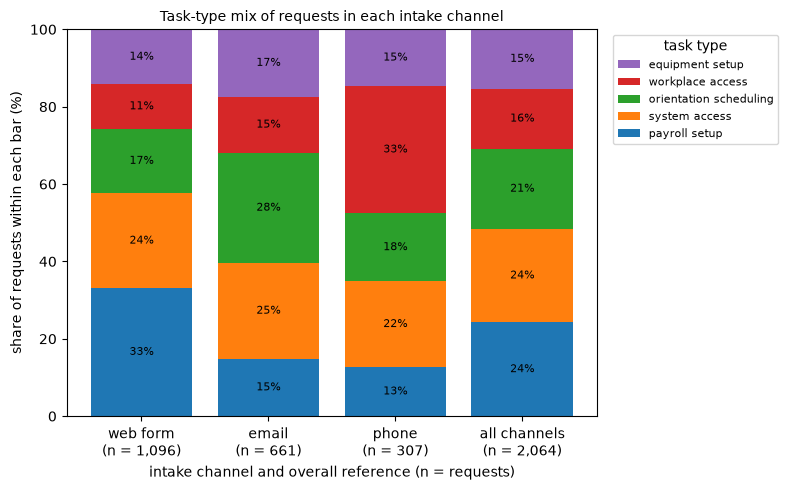

In [4]:
def stacked_task_mix(ax, pct, totals, title):
    """100% stacked bars: one bar per channel, one coloured segment per task type, labelled with percentages."""
    bottom = pd.Series(0.0, index=pct.columns)
    for task in TASK_TYPES:
        ax.bar(range(len(pct.columns)), pct.loc[task], bottom=bottom.values, label=task.replace("_", " "))
        for x, (share, base) in enumerate(zip(pct.loc[task], bottom)):
            if share >= 5:
                ax.text(x, base + share / 2, f"{share:.0f}%", ha="center", va="center", fontsize=8)
        bottom += pct.loc[task]
    ax.set_xticks(range(len(pct.columns)), [f"{c.replace('_', ' ')}\n(n = {totals[c]:,})" for c in pct.columns])
    ax.set_ylim(0, 100)
    ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(8, 5))
stacked_task_mix(ax, pct.drop(index="Total"), n.loc["Total"], "Task-type mix of requests in each intake channel")
ax.set_ylabel("share of requests within each bar (%)")
ax.set_xlabel("intake channel and overall reference (n = requests)")
handles, labels = ax.get_legend_handles_labels()  # reversed so the legend order matches the stacking
ax.legend(handles[::-1], labels[::-1], title="task type", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "task_mix_by_channel.png", dpi=120)
plt.show()

## D. Supporting check: field and office departments

Intake habits may differ by hiring department, so the main view is repeated using the generator's department groups: field (Parks, Transit, Utilities) and office (Recreation, Finance, Administration). The confirmed `hiring_department` is used because it is never blank.

This is a short descriptive check: it shows whether the pattern looks similar or different within each group. It does not measure how much of the overall association department composition explains. Counts are shown with every percentage because some groups are small.

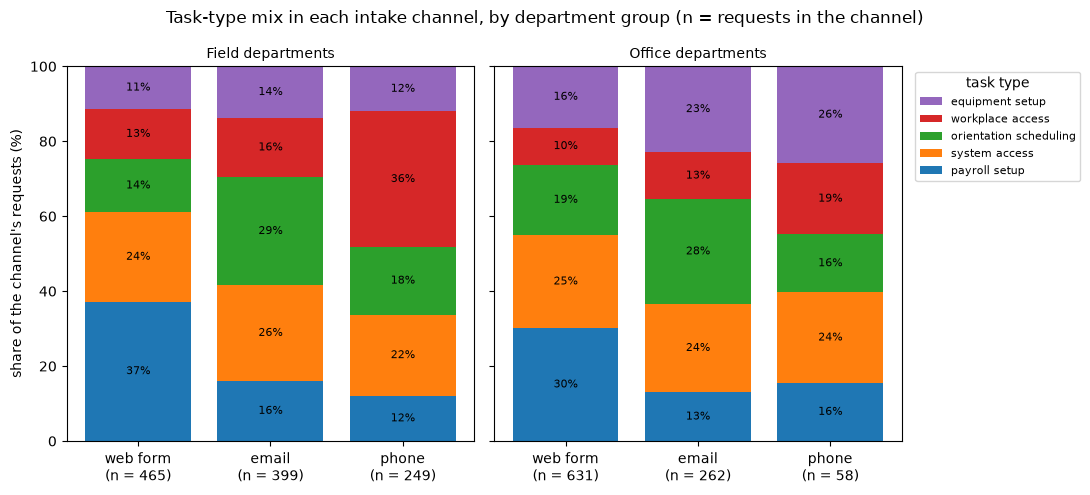

,employees,requests,web_form_requests,email_requests,phone_requests
department_group,,,,,
field,267,1113,465,399,249
office,233,951,631,262,58


,field_web_form_requests,field_web_form_%,field_email_requests,field_email_%,field_phone_requests,field_phone_%,office_web_form_requests,office_web_form_%,office_email_requests,office_email_%,office_phone_requests,office_phone_%
task_type,,,,,,,,,,,,
payroll_setup,173,37.2,64,16.0,30,12.0,190,30.1,34,13.0,9,15.5
system_access,111,23.9,102,25.6,54,21.7,157,24.9,62,23.7,14,24.1
orientation_scheduling,66,14.2,115,28.8,45,18.1,118,18.7,73,27.9,9,15.5
workplace_access,62,13.3,63,15.8,90,36.1,63,10.0,33,12.6,11,19.0
equipment_setup,53,11.4,55,13.8,30,12.0,103,16.3,60,22.9,15,25.9


In [5]:
requests["department_group"] = requests["hiring_department"].map(
    {**dict.fromkeys(FIELD_DEPARTMENTS, "field"), **dict.fromkeys(OFFICE_DEPARTMENTS, "office")})
GROUPS = ["field", "office"]

# Task-type mix within each channel, separately for each department group, with counts
group_tables = {}
for group in GROUPS:
    g_n, g_pct = counts_and_shares(requests[requests["department_group"] == group], "task_type", "intake_channel")
    group_tables[group] = (g_n.reindex(index=TASK_TYPES, columns=CHANNELS, fill_value=0),
                           g_pct.reindex(index=TASK_TYPES, columns=CHANNELS, fill_value=0))
task_mix_by_group = pd.DataFrame({f"{group}_{channel}_{m}": table[channel]
                                  for group, (g_n, g_pct) in group_tables.items() for channel in CHANNELS
                                  for m, table in [("requests", g_n), ("%", g_pct)]})
group_sizes = pd.DataFrame({"employees": requests.groupby("department_group")["employee_id"].nunique(),
                            "requests": requests["department_group"].value_counts(),
                            **{f"{c}_requests": requests[requests["intake_channel"] == c]["department_group"].value_counts()
                               for c in CHANNELS}}).reindex(GROUPS)

group_sizes.to_csv(OUTPUT_DIR / "department_group_sizes.csv")
task_mix_by_group.round(1).to_csv(OUTPUT_DIR / "task_mix_by_channel_and_department_group.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, group in zip(axes, GROUPS):
    g_n, g_pct = group_tables[group]
    stacked_task_mix(ax, g_pct, g_n.sum(), f"{group.capitalize()} departments")
axes[0].set_ylabel("share of the channel's requests (%)")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles[::-1], labels[::-1], title="task type", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("Task-type mix in each intake channel, by department group (n = requests in the channel)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "task_mix_by_department_group.png", dpi=120)
plt.show()

display(group_sizes)
task_mix_by_group.round(1)

## E. Interpretation

**Association.** In this generated dataset, task types make up different proportions of each channel's requests. Payroll setup is 33.1% of web-form requests (363 of 1,096), compared with 14.8% of email and 12.7% of phone requests. Orientation scheduling is the largest share of email requests, at 28.4% (188 of 661). Workplace access is 32.9% of phone requests (101 of 307), about twice its 15.6% share of all requests. System access (22.1–24.8%) and equipment setup (14.2–17.4%) vary less across channels than payroll setup, orientation scheduling, and workplace access.

**From the other direction.** 72.6% of payroll requests arrive by web form. Orientation scheduling is almost evenly split between email (44.1%) and web form (43.2%). Web form is still the most common channel for workplace access (38.8%), but workplace access has the highest phone share of any task type (31.4%).

**Department groups.** The pattern differs between field and office departments. Field departments sent 249 of the 307 phone requests, and office departments sent 58. Workplace access is 36.1% of field phone requests (90 of 249) but 19.0% of office phone requests (11 of 58). In both groups, payroll setup is the largest share of web-form requests and orientation scheduling is the largest share of email requests. This comparison is descriptive; it does not measure how much of the overall association department composition explains.

**Why the pattern appears here.** The AIDA 1141 Exercise 02 generator assigns channels using invented task-type adjustments (payroll toward web form, orientation toward email, workplace access toward phone), gives field departments higher phone and email use, and gives field employees a higher chance of needing workplace access. These settings shape the observed association, although this notebook does not separate their individual contributions.

**What the numbers do not show.** They do not show that channel causes task type, or the reverse, and they do not describe real HR intake. Requests are grouped within employees (about four tasks each, sharing one department), so they are not independent observations. Office phone requests are few (58 in total, 9–15 per task type), so those percentages could change noticeably with a few more or fewer requests.